# Figure 2
ODE and stochastic molecular model implementation examples

#### Load libraries
Add paths to PySB models in Python folder

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.insert(0, "../../Python/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, "../../Python/fit")

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from cell_cycle_death_model import model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    


In [3]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd() + '/../../Python/model_data/parameters.csv')
# del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [4]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/../../Python/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

## Fig2b


In [5]:
#change the model parameters of the model if needed
# omega = 200

# Directory containing cell fate data
DATADIR = Path('../../Data/Exp_Intermitotic_Times/')

In [6]:
plt.style.use('default')      # Necessary for plotting in PyCharm
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)
size = (3.5, 2.5)


In [7]:
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1
model.parameters['AKT'].value = 1

In [8]:
#ODE simulation

t_ode = np.linspace(0, 500, 5001)
simres = ScipyOdeSimulator(model, t_ode, verbose=False).run() #deterministic simulation
yout_ode = simres.all


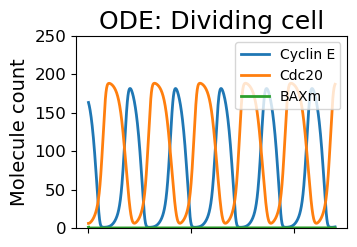

In [12]:
observables=['obsCycE','obsCdc20', 'obsBAXm'] #plot Cyclin E, Cdc20 and BAXm
label=['Cyclin E', 'Cdc20', 'BAXm']


fig= plt.figure(figsize=size)
for obs in range(3) :
    plt.plot(t_ode[:1200],yout_ode[observables[obs]][:1200], label=label[obs], lw=2)
plt.legend(loc=1)
# plt.xlabel('Time (h)')
plt.ylabel('Molecule count')
plt.title('ODE: Dividing cell')
plt.ylim(0, 250)
plt.xticks([0, 50, 100])

ax = plt.gca()
ax.tick_params(labelbottom=False)
ax.grid(False)
ax.set_xticks([0, 50, 100])

fig2b_fn = Path(SAVEDIR, 'fig2b.svg')

if SAVEFILES and (OVERWRITE or not fig2b_fn.exists()):
    plt.savefig(fig2b_fn, bbox_inches='tight')
else:
    plt.figure()

In [13]:
%%time

### Stochastic simulation

t_ssa = np.linspace(0, 120, 120001);
sim = BngSimulator(model, tspan=t_ssa, verbose=False); #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout_div = simres.observables;


CPU times: total: 1.69 s
Wall time: 7.22 s


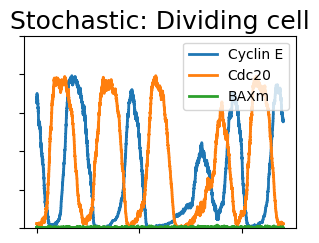

In [14]:
yout = simres.observables;
observables=['obsCycE','obsCdc20', 'obsBAXm']; #plot Cyclin E, Cdc20 and Cyclin A
label=['Cyclin E', 'Cdc20', 'BAXm']

fig = plt.figure(figsize=size)
for obs in range(3) :    
    plt.plot(t_ssa,yout_div[observables[obs]], label=label[obs], lw=2)
plt.legend(loc=1)
# plt.xlabel('Time (h)')
# plt.ylabel('Molecule count')
plt.title('Stochastic: Dividing cell')
plt.ylim(0, 250)

ax = plt.gca()
ax.tick_params(labelbottom=False)
ax.tick_params(labelleft=False)

fig2c_fn = Path(SAVEDIR, 'fig2c.svg')
if SAVEFILES and (OVERWRITE or not fig2c_fn.exists()):
    plt.savefig(fig2c_fn, bbox_inches='tight')
else:
    plt.figure()

### Set input parameter values to soft_ERL condition

In [15]:
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4
model.parameters['AKT'].value = 0.3

In [16]:
%%time

### Stochastic simulation
### random seed for quiescent cell == 1 or 5 (using VS Code)
### random seed for quiescent cell == 18 (for browser notebook)

# t = np.linspace(0, 120, 120001);
sim = BngSimulator(model, tspan=t_ssa, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=18) #running the simulation; remove seed for truly random; seed=1 used for quiescent cell
yout_qui = simres.observables;


CPU times: total: 1.7 s
Wall time: 6.84 s


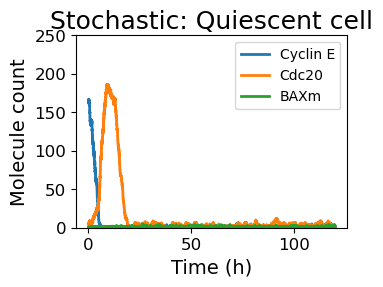

In [17]:
yout = simres.observables
observables=['obsCycE','obsCdc20', 'obsBAXm'] #plot Cyclin E, Cdc20 and BAXm
label=['Cyclin E', 'Cdc20', 'BAXm']

fig = plt.figure(figsize=size)
for obs in range(3) :    
    plt.plot(t_ssa,yout_qui[observables[obs]], label=label[obs], lw=2)
plt.legend(loc=1)
plt.xlabel('Time (h)')
plt.ylabel('Molecule count')
plt.title('Stochastic: Quiescent cell')
plt.ylim(0, 250)



fig2d_fn = Path(SAVEDIR, 'fig2d.svg')
if SAVEFILES and (OVERWRITE or not fig2d_fn.exists()):
    plt.savefig(fig2d_fn, bbox_inches='tight')
else:
    plt.figure()

In [18]:
%%time

### Stochastic simulation
### random seed for dying cell == 25 (using VS Code)

# t = np.linspace(0, 120, 120001)
sim = BngSimulator(model, tspan=t_ssa, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=25) #running the simulation; remove seed for truly random; seed=5 or 13 is used for dying cell

yout_apo = simres.observables

CPU times: total: 1.7 s
Wall time: 6.77 s


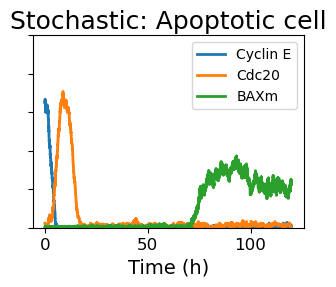

In [19]:
yout = simres.observables
observables=['obsCycE','obsCdc20', 'obsBAXm'] #plot Cyclin E, Cdc20 and Cyclin A
label=['Cyclin E', 'Cdc20', 'BAXm']

fig = plt.figure(figsize=size)
for obs in range(3) :    
    plt.plot(t_ssa,yout_apo[observables[obs]], label=label[obs], lw=2)
plt.legend(loc=1)
plt.xlabel('Time (h)')
# plt.ylabel('Molecule count')
plt.title('Stochastic: Apoptotic cell')
plt.ylim(0, 250)

ax = plt.gca()
ax.tick_params(labelleft=False)

fig2e_fn = Path(SAVEDIR, 'fig2e.svg')
if SAVEFILES and (OVERWRITE or not fig2e_fn.exists()):
    plt.savefig(fig2e_fn, bbox_inches='tight')
else:
    plt.figure()

In [20]:
params = {'axes.titlesize': 14}
plt.rcParams.update(params)

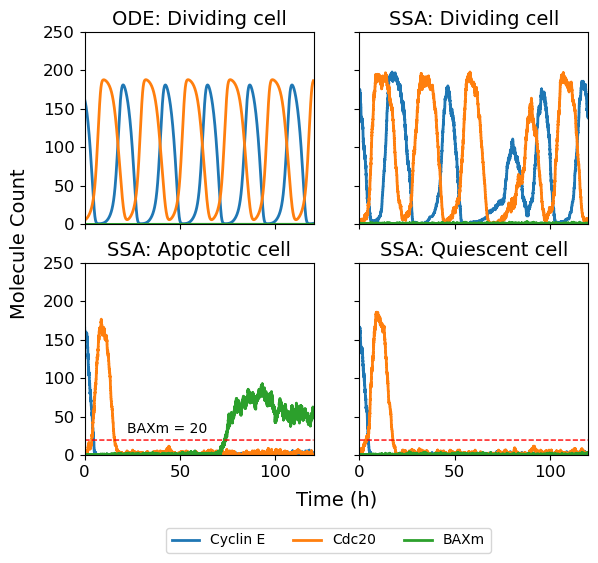

In [26]:
observables=['obsCycE','obsCdc20', 'obsBAXm'] #plot Cyclin E, Cdc20 and BAXm
label=['Cyclin E', 'Cdc20', 'BAXm']
baxm_thresh = [20]*len(t_ssa)

size = (6.5,5.5)
xmin = 0
xmax = 120
ymin = 0
ymax = 250

fig, axes = plt.subplots(2, 2, figsize=size)

for obs in range(3) :
    axes[0,0].plot(t_ode[:1200],yout_ode[observables[obs]][:1200], label=label[obs], lw=2)
axes[0,0].set_xlim([xmin, xmax])
axes[0,0].set_ylim([ymin, ymax])
axes[0,0].axes.xaxis.set_ticklabels([])
axes[0,0].set_title('ODE: Dividing cell')

for obs in range(3) :
    axes[0,1].plot(t_ssa,yout_div[observables[obs]], label=label[obs], lw=2)
axes[0,1].set_xlim([xmin, xmax])
axes[0,1].set_ylim([ymin, ymax])
axes[0,1].axes.xaxis.set_ticklabels([])
axes[0,1].axes.yaxis.set_ticklabels([])
axes[0,1].set_title('SSA: Dividing cell')

for obs in range(3) :
    axes[1,0].plot(t_ssa,yout_apo[observables[obs]], label=label[obs], lw=2)
axes[1,0].plot(t_ssa,baxm_thresh,c='red',lw=1,ls='--')
axes[1,0].text(22, 25, 'BAXm = 20', color='black', fontsize=10, va='bottom')
axes[1,0].set_xlim([xmin, xmax])
axes[1,0].set_ylim([ymin, ymax])
axes[1,0].set_title('SSA: Apoptotic cell')

for obs in range(3) :
    axes[1,1].plot(t_ssa,yout_qui[observables[obs]], label=label[obs], lw=2)
axes[1,1].plot(t_ssa,baxm_thresh,c='red',lw=1,ls='--')
axes[1,1].set_xlim([xmin, xmax])
axes[1,1].set_ylim([ymin, ymax])
axes[1,1].axes.yaxis.set_ticklabels([])
axes[1,1].set_title('SSA: Quiescent cell')



ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Molecule Count', labelpad=40)

fig.legend(label, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.08))

# plt.tight_layout(rect=[0, 0.05, 1, 1])  
fig2b = Path(SAVEDIR, 'fig2b_all.svg')
if SAVEFILES and (OVERWRITE or not fig2b.exists()):
    plt.savefig(fig2b, bbox_inches='tight')
else:
    plt.figure()